# Assignment 2 - Individual Checkpoint 2.

**Name:** Ritishka Gupta  
**Group ID:** Individual (I am working on my own, with no group)  
**Driving problem:** Q1 – *Do they achieve at least 7,000 steps on most days by avoiding long periods of inactivity?*  
**Personal Planning and Progress wiki page:** [Personal Planning and Progress ‐ Ritishka Gupta](https://github.com/rgup0018/assignment-2-data3406/wiki/Personal-Planning-and-Progress-%E2%80%90-Ritishka-Gupta)

**People explored in Checkpoint 1:**

| Id | Role in Checkpoint 1 |
|---|---|
| 8877689391 | high average stepper (16,040 steps/day) |
| 4558609924 | middle average stepper (7,685 steps/day) |
| 2320127002 | low average stepper (4,717 steps/day) |

**Person reported in Checkpoint 2:** **Id 4558609924**

**How I decided:** in Checkpoint 1 this person was the borderline case. They reached 7,000 steps on 58% of days, so whether they meet the goal on "most days" depends on the definitions I choose, which makes them the most informative test of the driving problem. They also wore the device well (no 0-step days), so their long inactive periods are less likely to be caused by not wearing the Fitbit than for the low stepper (Id 2320127002), and they have enough days below 7,000 steps to compare with goal days, unlike the high stepper (Id 8877689391), who missed only one day.

## Statement of help received
I am working individually, so I received **no help from team members** and **no help from other people**.


## Definitions and rationale
The driving problem does not define "most days", "long periods of inactivity" or which days count. These are my definitions, and every value is a constant in the Setup cell, so it can be changed.

| Term | My definition | Why | Trade-off |
|---|---|---|---|
| Daily steps | Sum of the **minute** data for the day | It is the same source as the inactivity measure, and the daily file's 12 May is a partial day (Checkpoint 1) | The daily file can be a few steps higher; checked below |
| Valid day | A complete day (1,440 minutes) with **at least 10 hours that contain one or more steps** | Tang et al. (2018) show that results depend on how a valid wear day is defined and compare day-level and hour-level rules. An hour-level rule removes days the device was worn only briefly (e.g. 01 May for Id 2320127002 in Checkpoint 1) | A valid day can still contain short periods without the device |
| 7,000-step goal | At least 7,000 steps in the day | Given in the driving problem; Paluch et al. (2022) found a lower risk of death in adults who take about 7,000 or more steps per day | |
| Most days | **More than half** of valid days (> 50%). I also report a stricter reading: at least 5 days in every 7 (≥ 71.4%) | The Australian guidelines ask adults to be active on most days, preferably every day, without giving a number | > 50% is the literal meaning; 5 of 7 is a common everyday meaning |
| Waking window | The **16 consecutive hours** in which the person most often has steps, estimated from their own data | There is no sleep data in these files, and Checkpoint 1 showed that a fixed 07:00–21:59 window does not suit everyone | The window cannot wrap past midnight |
| Inactive minute | A minute with **0–19 steps** | Tudor-Locke et al. (2018) describe 0 steps/min as non-movement and 1–19 steps/min as incidental stepping, i.e. no purposeful walking | A person standing and shuffling counts as inactive |
| Long period of inactivity | At least **60 consecutive inactive minutes** between the first and last step of the day within the waking window | The Australian guidelines warn against long periods of sitting without giving a length; 60 minutes is my choice, so I test 30 and 90 minutes too | Time before the first step or after the last step is not counted, because the person is probably asleep or not wearing the device |

## Initial assumptions and predictions for Id 4558609924
Written **before** running the analysis, based on my Checkpoint 1 results for this person.

**Assumptions**

- A1. `Id` 4558609924 is the same person in the daily and minute files, with about 30 days of data from 12 Apr to 12 May 2016.
- A2. A minute with no row in the minute file is missing data, not zero steps.
- A3. An hour with no steps at all during the day is more likely to mean the Fitbit was not worn than that the person sat still for a full hour.
- A4. The person sleeps about 8 hours, so 16 hours a day is a reasonable waking window.

**Predictions**

- P1. After removing days that are not valid, about **55–65%** of days will reach 7,000 steps. This would meet "most days" (> 50%) but not the stricter 5-of-7 reading.
- P2. Days below 7,000 steps will have **more time in long inactive periods** than goal days. (In Checkpoint 1 the longest zero-step run was 75 min on goal days and 189 min on other days.)
- P3. The waking window will start **later than 07:00**, because in Checkpoint 1 this person had few steps early in the morning.
- P4. The extra steps on goal days will come mainly from the **afternoon**.

## Setup


In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle

DATA_DIR = Path("data")
PERSON_ID = 4558609924     # change this to analyse any other person in the dataset

# Definitions (see the table above)
STEP_GOAL = 7000           # daily step goal from the driving problem
MIN_VALID_HOURS = 10       # valid day: at least 10 hours with one or more steps
WAKING_HOURS = 16          # waking window: 24 h minus about 8 h of sleep
INACTIVE_MAX_STEPS = 19    # inactive minute: 0-19 steps (no purposeful walking)
LONG_BOUT_MIN = 60         # long inactive period: >= 60 consecutive inactive minutes
MOST_DAYS = 0.5            # "most days": more than half of valid days
STRICT_DAYS = 5 / 7        # stricter reading: at least 5 days in every 7

GOAL_COLOUR, MISS_COLOUR, EXCLUDED_COLOUR = "#2a78d6", "#eb6834", "#b8b6b0"
TEXT_COLOUR = "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.titleweight": "bold",
    }
)

## Load the data


In [18]:
daily = pd.read_csv(DATA_DIR / "dailySteps_merged.csv")
minute_wide = pd.read_csv(DATA_DIR / "minuteStepsWide_merged.csv")

daily["ActivityDay"] = pd.to_datetime(daily["ActivityDay"], format="%m/%d/%Y")
minute_wide["ActivityHour"] = pd.to_datetime(
    minute_wide["ActivityHour"], format="%m/%d/%Y %I:%M:%S %p"
)

ALL_IDS = sorted(minute_wide["Id"].unique())
print(f"daily file:  {len(daily):>6,} rows, {daily['Id'].nunique()} people")
print(
    f"minute file: {len(minute_wide):>6,} rows (one per person-hour), {len(ALL_IDS)} people"
)
print(f"Person {PERSON_ID} is in the minute file: {PERSON_ID in ALL_IDS}")

daily file:     940 rows, 33 people
minute file: 21,645 rows (one per person-hour), 33 people
Person 4558609924 is in the minute file: True


**Result:** both files contain the same 33 people, and the chosen person is in the minute file, so the analysis can run.

## Functions


In [19]:
def person_minutes(pid):
    """One row per minute for one person, with a full timestamp, the day and the hour."""
    wide = minute_wide[minute_wide["Id"] == pid]
    long = wide.melt(id_vars=["Id", "ActivityHour"], var_name="col", value_name="Steps")
    long["Timestamp"] = long["ActivityHour"] + pd.to_timedelta(
        long["col"].str[-2:].astype(int), unit="min"
    )
    long["Day"] = long["Timestamp"].dt.normalize()
    long["Hour"] = long["Timestamp"].dt.hour
    return (
        long.drop(columns=["col", "ActivityHour"])
        .sort_values("Timestamp")
        .reset_index(drop=True)
    )


def day_table(pid, minutes):
    """One row per day: minute-based steps, wear information and the daily-file total."""
    days = minutes.groupby("Day").agg(Minutes=("Steps", "size"), Steps=("Steps", "sum"))
    days["ValidHours"] = minutes[minutes["Steps"] > 0].groupby("Day")["Hour"].nunique()
    days["ValidHours"] = days["ValidHours"].fillna(0).astype(int)
    days["Complete"] = days["Minutes"] == 24 * 60
    days["Valid"] = days["Complete"] & (days["ValidHours"] >= MIN_VALID_HOURS)
    days["Goal"] = days["Steps"] >= STEP_GOAL
    daily_file = daily[daily["Id"] == pid].set_index("ActivityDay")["StepTotal"]
    days["DailyFileSteps"] = daily_file.reindex(days.index)
    return days

In [20]:
def estimate_waking_start(minutes, days):
    """Start hour of the WAKING_HOURS-long window in which this person most often moves.

    For each hour of the day, find the share of valid days with at least one step in
    that hour, then choose the start hour whose window has the largest total share.
    The window does not wrap past midnight. Falls back to 07:00 if there are no valid days.
    """
    valid_minutes = minutes[minutes["Day"].isin(days.index[days["Valid"]])]
    if valid_minutes.empty:
        return 7
    hour_has_steps = valid_minutes.groupby(["Day", "Hour"])["Steps"].sum().gt(0)
    share_by_hour = (
        hour_has_steps.groupby("Hour").mean().reindex(range(24), fill_value=0)
    )
    window_totals = share_by_hour.rolling(WAKING_HOURS).sum().shift(-(WAKING_HOURS - 1))
    return int(window_totals.idxmax())


def inactive_runs(minutes, start_hour, inactive_max=INACTIVE_MAX_STEPS):
    """Every run of consecutive inactive minutes (at most inactive_max steps) between
    the first and last step of each day's waking window. Time before the first step or
    after the last step is not counted: the person is probably still asleep or not
    wearing the device.
    """
    window = minutes[minutes["Hour"].between(start_hour, start_hour + WAKING_HOURS - 1)]
    stepping = (
        window.loc[window["Steps"] > 0].groupby("Day")["Timestamp"].agg(["min", "max"])
    )
    bounds = stepping.reindex(window["Day"]).set_axis(window.index)
    awake = window[window["Timestamp"].between(bounds["min"], bounds["max"])]
    inactive = awake["Steps"].le(inactive_max)
    new_run = inactive.ne(inactive.shift()) | awake["Day"].ne(awake["Day"].shift())
    run_id = new_run.cumsum()
    runs = (
        awake[inactive]
        .groupby(run_id[inactive])
        .agg(
            Day=("Day", "first"),
            Start=("Timestamp", "first"),
            Minutes=("Steps", "size"),
        )
    )
    runs["End"] = runs["Start"] + pd.to_timedelta(runs["Minutes"], unit="min")
    return runs.reset_index(drop=True)

In [21]:
def analyse_person(pid, bout_min=LONG_BOUT_MIN, inactive_max=INACTIVE_MAX_STEPS):
    """Run the whole pipeline for one person; return the pieces used by tables and plots."""
    minutes = person_minutes(pid)
    days = day_table(pid, minutes)
    start = estimate_waking_start(minutes, days)
    runs = inactive_runs(minutes, start, inactive_max)
    bouts = runs[runs["Minutes"] >= bout_min]

    days["LongestInactive"] = (
        runs.groupby("Day")["Minutes"].max().reindex(days.index).fillna(0)
    )
    days["LongBouts"] = bouts.groupby("Day").size().reindex(days.index, fill_value=0)
    days["LongBoutMinutes"] = (
        bouts.groupby("Day")["Minutes"].sum().reindex(days.index, fill_value=0)
    )
    awake_steps = minutes[
        (minutes["Steps"] > 0)
        & minutes["Hour"].between(start, start + WAKING_HOURS - 1)
    ]
    first_step = awake_steps.groupby("Day")["Timestamp"].min()
    days["FirstStepHour"] = (
        (first_step - first_step.index) / pd.Timedelta(hours=1)
    ).reindex(days.index)
    return {
        "pid": pid,
        "minutes": minutes,
        "days": days,
        "bouts": bouts,
        "wake_start": start,
        "bout_min": bout_min,
        "inactive_max": inactive_max,
    }


def rank_correlation(x, y):
    """Spearman rank correlation (Pearson correlation of the ranks).
    NaN if there are fewer than 3 days or one of the measures never changes."""
    if len(x) < 3 or x.nunique() < 2 or y.nunique() < 2:
        return np.nan
    return x.rank().corr(y.rank())


def summarise(result):
    """Key numbers for the driving problem, using valid days only."""
    valid = result["days"][result["days"]["Valid"]]
    goal, miss = valid[valid["Goal"]], valid[~valid["Goal"]]
    share = len(goal) / len(valid) if len(valid) else np.nan
    start = result["wake_start"]
    return pd.Series(
        {
            "valid days": len(valid),
            "goal days": len(goal),
            "% goal days": round(100 * share, 1) if len(valid) else np.nan,
            "most days (>50%)": bool(share > MOST_DAYS) if len(valid) else None,
            "strict (>=5 of 7)": bool(share >= STRICT_DAYS) if len(valid) else None,
            "waking window": f"{start:02d}:00-{start + WAKING_HOURS - 1:02d}:59",
            "median long-bout min, goal days": goal["LongBoutMinutes"].median(),
            "median long-bout min, other days": miss["LongBoutMinutes"].median(),
            "rank corr: long-bout min vs steps": round(
                rank_correlation(valid["LongBoutMinutes"], valid["Steps"]), 2
            ),
        },
        name=result["pid"],
    )

## Run the analysis for the chosen person

In [22]:
result = analyse_person(PERSON_ID)
days = result["days"]
print(
    f"Person {PERSON_ID}: {len(days)} days of minute data, {days['Complete'].sum()} complete, "
    f"{days['Valid'].sum()} valid"
)
print(
    f"Estimated waking window: {result['wake_start']:02d}:00 to "
    f"{result['wake_start'] + WAKING_HOURS - 1:02d}:59"
)

Person 4558609924: 30 days of minute data, 29 complete, 27 valid
Estimated waking window: 08:00 to 23:59


**Result:** the person has 30 days of minute data, of which 29 are complete and 27 are valid. The estimated waking window is **08:00 to 23:59**, so prediction **P3 is confirmed**: this person's day starts and ends about an hour later than the fixed 07:00–21:59 window I used in Checkpoint 1.

## Which days count? (adherence)
**Step:** count how many days reach 7,000 steps under four rules for which days count, from "every day in the daily file" to my valid-day rule.  
**Rationale:** Tang et al. (2018) showed that the definition of a valid day can change the conclusions drawn from tracker data, so I check how much it matters here before answering the driving problem.

In [23]:
def adherence_table(result):
    """How the share of goal days changes with the rule used to decide which days count."""
    days, pid = result["days"], result["pid"]
    file_days = daily[daily["Id"] == pid]
    rules = {
        "all days in the daily file (daily-file totals)": (
            file_days["StepTotal"] >= STEP_GOAL
        ),
        "days with any minute data": days["Goal"],
        "complete days (1,440 minutes)": days.loc[days["Complete"], "Goal"],
        "valid days (my rule, used below)": days.loc[days["Valid"], "Goal"],
    }
    table = pd.DataFrame(
        {
            "days": [len(g) for g in rules.values()],
            "goal days": [int(g.sum()) for g in rules.values()],
        },
        index=rules.keys(),
    )
    table["% goal days"] = (100 * table["goal days"] / table["days"]).round(1)
    return table


adherence_table(result)

,days,goal days,% goal days
all days in the daily file (daily-file totals),31,18,58.1
days with any minute data,30,19,63.3
"complete days (1,440 minutes)",29,18,62.1
"valid days (my rule, used below)",27,18,66.7


**Interpretation:** the rule matters but does not change the answer. The share of goal days rises from **58.1%** (all 31 days in the daily file) to **66.7%** (27 valid days), because the rules remove days with incomplete data, which tend to have low totals. Under every rule the share is above 50%, so the person meets the goal on "most days". Under no rule does it reach 5 days in 7 (71.4%).

In [24]:
days.loc[~days["Valid"], ["Minutes", "ValidHours", "Steps", "DailyFileSteps"]]

,Minutes,ValidHours,Steps,DailyFileSteps
Day,,,,
2016-04-13,1440,8,4978,4978
2016-05-08,1440,9,6543,6543
2016-05-12,1260,14,9995,6307


**Interpretation:** three days are removed, all for good reasons. **13 Apr** (8 hours with steps) and **8 May** (9 hours) were complete days but the person's steps only start around midday (see Figure 2), which suggests the device was put on late. **12 May** is incomplete, because the minute file stops at 20:59. Both 13 Apr and 8 May are below 7,000 steps, so keeping them would make the person look less active than they were. This supports assumption A3.

In [25]:
check = days[days["Complete"]].copy()
check["Difference"] = check["DailyFileSteps"] - check["Steps"]
print(
    f"complete days where the daily file differs from the minute total: "
    f"{check['Difference'].ne(0).sum()} of {len(check)}"
)
print(
    f"largest difference: {check['Difference'].abs().max():.0f} steps "
    f"({check['Difference'].abs().max() / check['Steps'].mean():.1%} of an average day)"
)
status_changes = (check["DailyFileSteps"] >= STEP_GOAL) != check["Goal"]
print(f"days whose goal status changes: {status_changes.sum()}")

complete days where the daily file differs from the minute total: 3 of 29
largest difference: 24 steps (0.3% of an average day)
days whose goal status changes: 0


**Interpretation:** for this person the two sources agree closely. Only 3 of 29 complete days differ, by at most 24 steps (0.3% of an average day), and no day changes goal status. Using minute totals therefore does not affect the answer, and it keeps the step totals and the inactivity measure from the same source.

## Part 1: does this person reach 7,000 steps on most days?


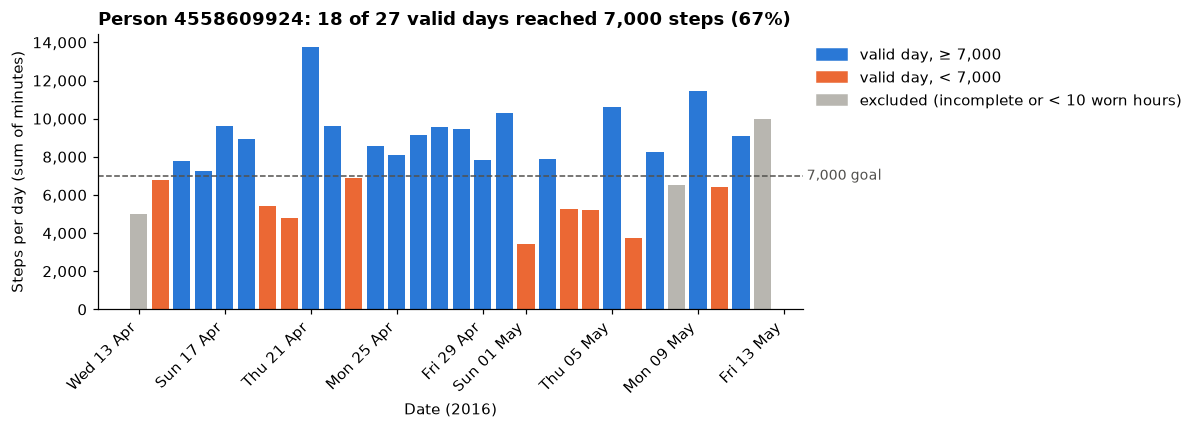

In [26]:
def plot_daily_steps(result):
    """Bar chart of steps per day; bars coloured by goal status, excluded days in grey."""
    days, pid = result["days"], result["pid"]
    colours = np.where(
        ~days["Valid"],
        EXCLUDED_COLOUR,
        np.where(days["Goal"], GOAL_COLOUR, MISS_COLOUR),
    )
    valid = days[days["Valid"]]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(days.index, days["Steps"], color=colours, width=0.8)
    ax.axhline(STEP_GOAL, color=TEXT_COLOUR, linestyle="--", linewidth=1)
    ax.text(
        1.005,
        STEP_GOAL,
        f"{STEP_GOAL:,} goal",
        color=TEXT_COLOUR,
        fontsize=9,
        va="center",
        transform=ax.get_yaxis_transform(),
    )
    ax.set_title(
        f"Person {pid}: {valid['Goal'].sum()} of {len(valid)} valid days reached "
        f"{STEP_GOAL:,} steps ({valid['Goal'].mean():.0%})",
        loc="left",
    )
    ax.set_xlabel("Date (2016)")
    ax.set_ylabel("Steps per day (sum of minutes)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.legend(
        handles=[
            Patch(color=GOAL_COLOUR, label=f"valid day, ≥ {STEP_GOAL:,}"),
            Patch(color=MISS_COLOUR, label=f"valid day, < {STEP_GOAL:,}"),
            Patch(
                color=EXCLUDED_COLOUR, label="excluded (incomplete or < 10 worn hours)"
            ),
        ],
        loc="upper left",
        bbox_to_anchor=(1, 1),
        frameon=False,
    )
    plt.tight_layout()
    plt.show()


plot_daily_steps(result)

**Interpretation (Figure 1):** **18 of 27 valid days (67%)** reached 7,000 steps. The missed days are spread across the month rather than grouped in one week, and three of them (14 Apr, 23 Apr and 10 May) were within about 600 steps of the goal. Prediction **P1 is mostly confirmed**: the share is slightly above my 55–65% range, and as predicted it meets "most days" (> 50%) but not 5 days in 7 (71.4%).

## Part 2: is this by avoiding long periods of inactivity?


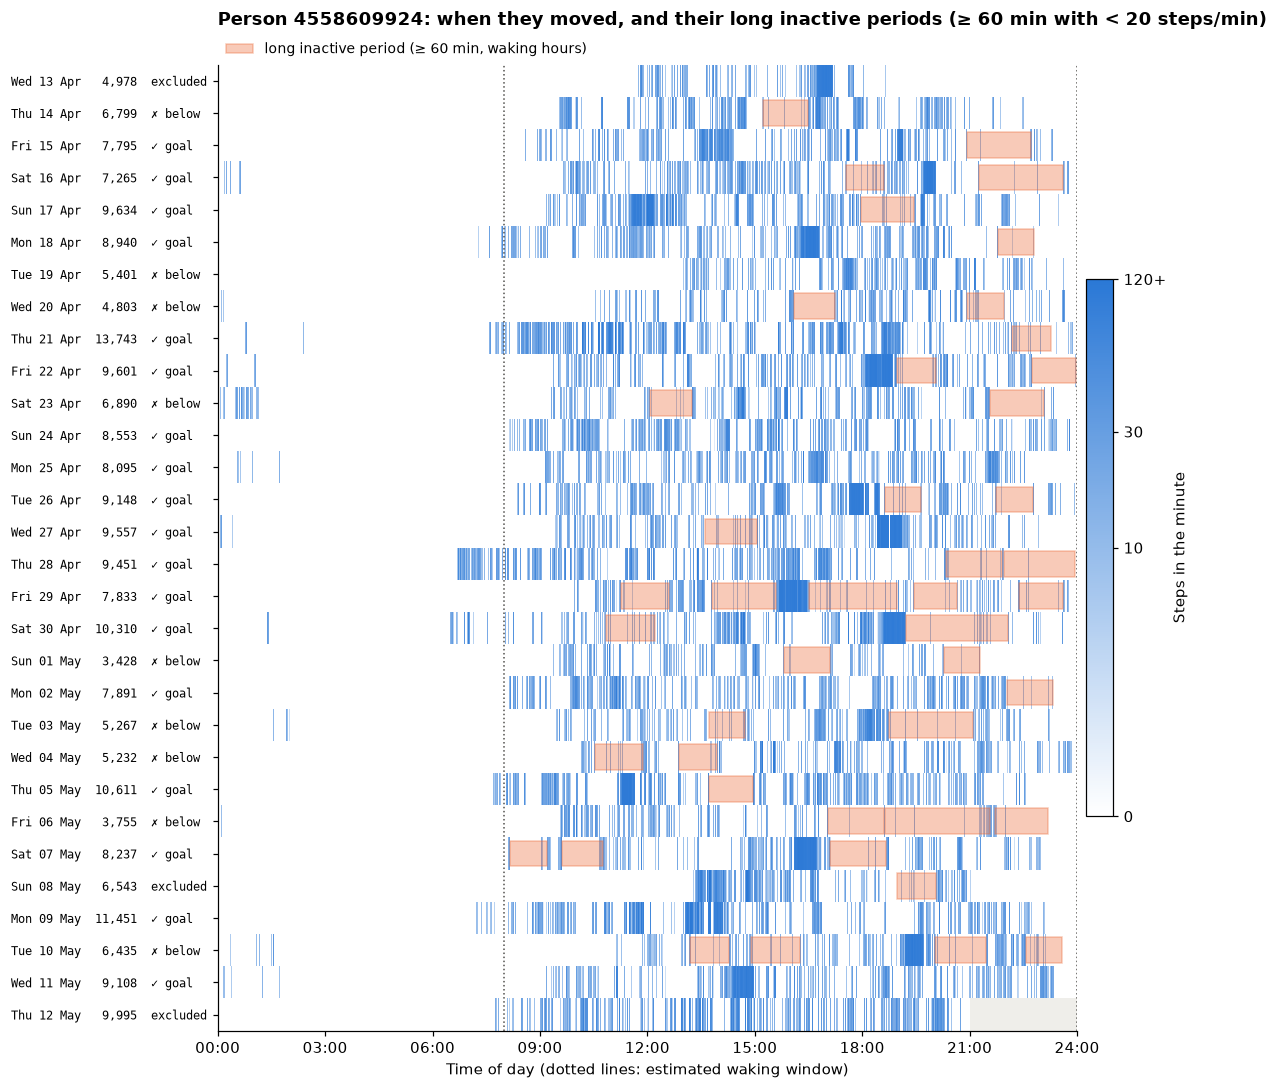

In [27]:
def plot_day_timeline(result):
    """One row per day: steps in every minute (blue), long inactive periods in orange."""
    days, minutes, bouts = result["days"], result["minutes"], result["bouts"]
    grid = minutes.pivot_table(
        index="Day",
        columns=minutes["Hour"] * 60 + minutes["Timestamp"].dt.minute,
        values="Steps",
    ).reindex(index=days.index, columns=range(1440))
    cmap = LinearSegmentedColormap.from_list("steps", ["#ffffff", GOAL_COLOUR])
    cmap.set_bad("#efeeea")  # minutes with no data
    fig, ax = plt.subplots(figsize=(11, 0.28 * len(days) + 1.6))
    image = ax.imshow(
        np.log1p(grid),
        aspect="auto",
        cmap=cmap,
        vmin=0,
        vmax=np.log1p(120),
        extent=(0, 24, len(days) - 0.5, -0.5),
        interpolation="nearest",
    )
    row = {day: i for i, day in enumerate(days.index)}
    for bout in bouts.itertuples():
        start = bout.Start.hour + bout.Start.minute / 60
        ax.add_patch(
            Rectangle(
                (start, row[bout.Day] - 0.4),
                bout.Minutes / 60,
                0.8,
                facecolor=MISS_COLOUR,
                alpha=0.35,
                edgecolor=MISS_COLOUR,
                linewidth=1,
            )
        )
    for hour in (result["wake_start"], result["wake_start"] + WAKING_HOURS):
        ax.axvline(hour, color=TEXT_COLOUR, linestyle=":", linewidth=1)
    status = np.where(
        ~days["Valid"], "excluded", np.where(days["Goal"], "✓ goal", "✗ below")
    )
    labels = [
        f"{day:%a %d %b} {steps:>7,}  {label:<8}"
        for day, steps, label in zip(days.index, days["Steps"], status)
    ]
    ax.set_yticks(range(len(days)), labels, fontsize=8, family="DejaVu Sans Mono")
    ax.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
    ax.set_xlabel("Time of day (dotted lines: estimated waking window)")
    ax.set_title(
        f"Person {result['pid']}: when they moved, and their long inactive periods "
        f"(≥ {result['bout_min']} min with < {result['inactive_max'] + 1} steps/min)",
        loc="left",
        pad=26,
    )
    cbar = fig.colorbar(image, ax=ax, pad=0.01, fraction=0.03)
    cbar.set_ticks(np.log1p([0, 10, 30, 120]), labels=["0", "10", "30", "120+"])
    cbar.set_label("Steps in the minute")
    ax.legend(
        handles=[
            Patch(
                facecolor=MISS_COLOUR,
                alpha=0.35,
                edgecolor=MISS_COLOUR,
                label=f"long inactive period (≥ {result['bout_min']} min, waking hours)",
            )
        ],
        loc="lower left",
        bbox_to_anchor=(0, 1.0),
        frameon=False,
        fontsize=9,
        borderaxespad=0.2,
    )
    plt.tight_layout()
    plt.show()


plot_day_timeline(result)

**Interpretation (Figure 2):** long inactive periods are common on **both kinds of day**: 14 of 18 goal days and 8 of 9 other days have at least one. Most of them (26 of 43 on valid days) start at **17:00 or later**, so this person's longest inactive periods are mainly in the evening. Two other patterns stand out. Several days below the goal start late (19 Apr starts around 13:00, 20 Apr and 10 May after 10:30), and the worst day, **06 May** (3,755 steps), has almost no walking after 17:00. On the other hand, 29 Apr reached the goal despite five long inactive periods, because of a burst of walking around 15:00–16:30.

In [28]:
def goal_comparison(result):
    """Inactivity measures on goal days and other valid days (medians)."""
    valid = result["days"][result["days"]["Valid"]]
    table = valid.groupby(
        valid["Goal"].map(
            {True: f">= {STEP_GOAL:,} steps", False: f"< {STEP_GOAL:,} steps"}
        )
    ).agg(
        days=("Steps", "size"),
        median_steps=("Steps", "median"),
        median_long_bouts=("LongBouts", "median"),
        median_long_bout_minutes=("LongBoutMinutes", "median"),
        median_longest_inactive_minutes=("LongestInactive", "median"),
        days_with_no_long_bout=("LongBouts", lambda b: int(b.eq(0).sum())),
        median_first_step=("FirstStepHour", "median"),
    )
    table["median_first_step"] = table["median_first_step"].map(
        lambda h: f"{int(h):02d}:{round(h % 1 * 60):02d}"
    )
    return table.round(1).T.rename_axis(
        "measure (valid days)"
    )  # one column per group of days


goal_comparison(result)

Goal,"< 7,000 steps",">= 7,000 steps"
measure (valid days),,
days,9,18
median_steps,5267.0,9128.0
median_long_bouts,2.0,1.0
median_long_bout_minutes,144.0,87.5
median_longest_inactive_minutes,80.0,75.0
days_with_no_long_bout,1,4
median_first_step,09:34,08:15


**Interpretation:** on days below 7,000 steps the person spent a median **144 min** in long inactive periods, against **88 min** on goal days, and had 2 such periods rather than 1. Only 1 of the 9 days below the goal had no long inactive period, compared with 4 of 18 goal days. However, the longest single inactive run is almost the same (80 vs 75 min). The clearest difference is when the day starts: the median first step is at **09:34** on days below the goal and **08:15** on goal days.

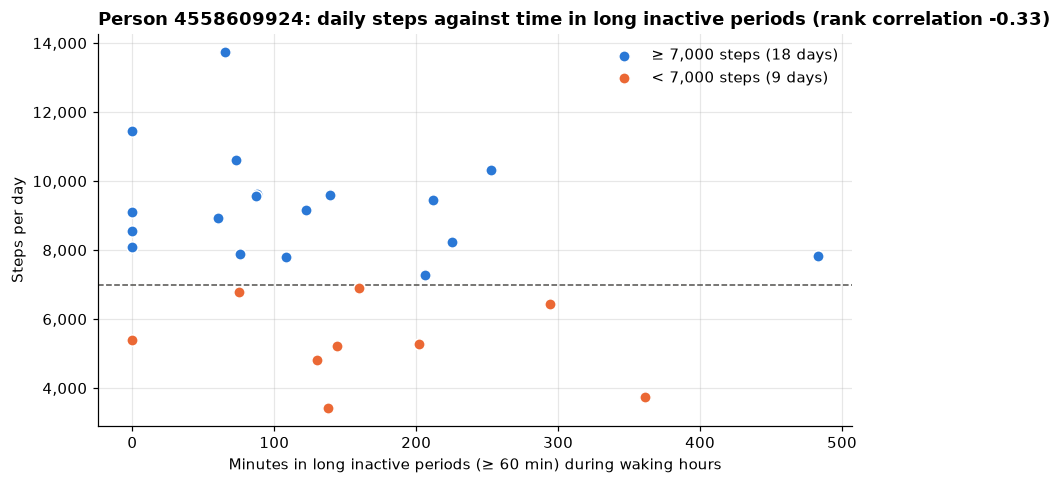

In [29]:
def plot_inactivity_vs_steps(result):
    """Scatter of minutes in long inactive periods against daily steps, for valid days."""
    valid = result["days"][result["days"]["Valid"]]
    rho = rank_correlation(valid["LongBoutMinutes"], valid["Steps"])
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for met, colour, label in [
        (True, GOAL_COLOUR, f"≥ {STEP_GOAL:,} steps"),
        (False, MISS_COLOUR, f"< {STEP_GOAL:,} steps"),
    ]:
        part = valid[valid["Goal"] == met]
        ax.scatter(
            part["LongBoutMinutes"],
            part["Steps"],
            s=55,
            color=colour,
            edgecolor="white",
            linewidth=1,
            label=f"{label} ({len(part)} days)",
            zorder=3,
        )
    ax.axhline(STEP_GOAL, color=TEXT_COLOUR, linestyle="--", linewidth=1)
    ax.set_title(
        f"Person {result['pid']}: daily steps against time in long inactive periods "
        f"(rank correlation {rho:.2f})",
        loc="left",
    )
    ax.set_xlabel(
        f"Minutes in long inactive periods (≥ {result['bout_min']} min) during waking hours"
    )
    ax.set_ylabel("Steps per day")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


plot_inactivity_vs_steps(result)

**Interpretation (Figure 3):** the points slope downwards, but only weakly (rank correlation **−0.33**). The two groups overlap: several goal days have 200 or more minutes in long inactive periods, and one day below the goal (19 Apr) has none. Prediction **P2 is confirmed in direction but weaker** than Checkpoint 1 suggested. In Checkpoint 1 the measure included the time before the first step of the morning, which made days with a late start look much more inactive.

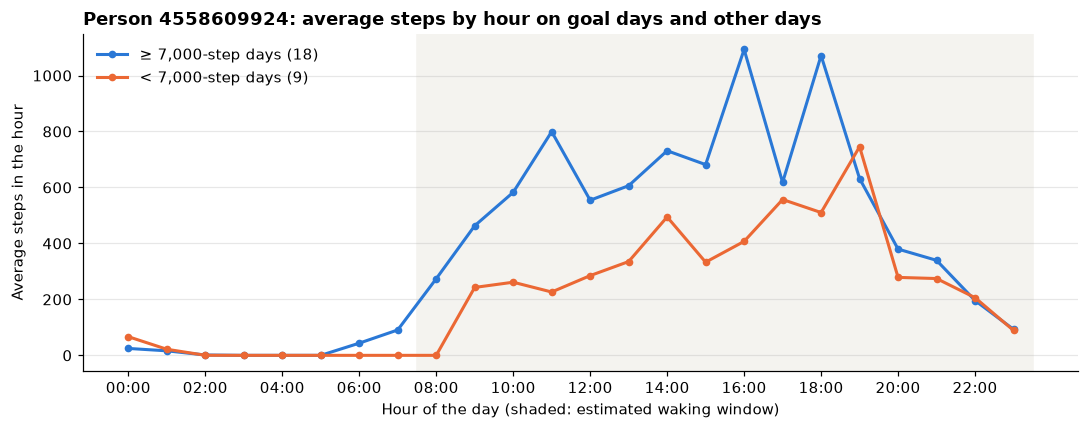

Hours with the largest average gap (goal days minus other days):
Hour
16    686.0
11    573.0
18    561.0
15    349.0


In [30]:
def plot_hourly_profile(result):
    """Average steps in each hour of the day, on goal days and on other valid days."""
    days, minutes = result["days"], result["minutes"]
    valid_days = days[days["Valid"]]
    hourly = (
        minutes[minutes["Day"].isin(valid_days.index)]
        .groupby(["Day", "Hour"])["Steps"]
        .sum()
        .unstack()
    )
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.axvspan(
        result["wake_start"] - 0.5,
        result["wake_start"] + WAKING_HOURS - 0.5,
        color="#f4f3ef",
        zorder=0,
    )
    for met, colour, label in [
        (True, GOAL_COLOUR, f"≥ {STEP_GOAL:,}"),
        (False, MISS_COLOUR, f"< {STEP_GOAL:,}"),
    ]:
        profile = hourly.loc[valid_days.index[valid_days["Goal"] == met]].mean()
        if profile.notna().any():
            ax.plot(
                profile.index,
                profile.values,
                color=colour,
                linewidth=2,
                marker="o",
                markersize=4,
                label=f"{label}-step days ({(valid_days['Goal'] == met).sum()})",
            )
    ax.set_xticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
    ax.set_xlabel("Hour of the day (shaded: estimated waking window)")
    ax.set_ylabel("Average steps in the hour")
    ax.set_title(
        f"Person {result['pid']}: average steps by hour on goal days and other days",
        loc="left",
    )
    ax.grid(axis="y", alpha=0.3)
    ax.legend(frameon=False, loc="upper left")
    plt.tight_layout()
    plt.show()
    return (
        hourly.loc[valid_days.index[valid_days["Goal"]]].mean()
        - hourly.loc[valid_days.index[~valid_days["Goal"]]].mean()
    )


hour_gap = plot_hourly_profile(result)
print("Hours with the largest average gap (goal days minus other days):")
print(hour_gap.sort_values(ascending=False).head(4).round(0).to_string())

**Interpretation (Figure 4):** goal days have more steps in **every hour from 07:00 to 18:00**, and the largest gaps are at 16:00 (+686 steps), 11:00 (+573) and 18:00 (+561). After 19:00 the two lines are almost the same. So the extra steps on goal days come from walking more during the day and starting earlier, not from a better evening. Prediction **P4 is only partly confirmed**: the afternoon matters, but so do the morning and late morning.

## Sensitivity check


In [31]:
settings = {
    "< 20 steps/min, >= 30 min": (30, 19),
    "< 20 steps/min, >= 60 min (used)": (60, 19),
    "< 20 steps/min, >= 90 min": (90, 19),
    "0 steps/min, >= 60 min": (60, 0),
}
rows = [
    "median long-bout min, goal days",
    "median long-bout min, other days",
    "rank corr: long-bout min vs steps",
]
sensitivity = pd.DataFrame(
    {
        name: summarise(analyse_person(PERSON_ID, bout_min=b, inactive_max=i))[rows]
        for name, (b, i) in settings.items()
    }
)
sensitivity.columns.name = "long inactive period"
sensitivity

long inactive period,"< 20 steps/min, >= 30 min","< 20 steps/min, >= 60 min (used)","< 20 steps/min, >= 90 min","0 steps/min, >= 60 min"
"median long-bout min, goal days",320.5,87.5,0.0,0.0
"median long-bout min, other days",405.0,144.0,0.0,0.0
rank corr: long-bout min vs steps,-0.34,-0.33,-0.18,-0.03


**Interpretation:** the direction of the result holds when a long period is 30 or 60 minutes (more inactive time on days below the goal, rank correlation about −0.33). At 90 minutes most days have no long period at all, so the medians are 0 and the link almost disappears (−0.18). With the strict zero-steps rule the person has almost no long inactive periods, because a single step ends the run. This is why I use the cadence-based rule.

## Check: does the code work for every person?


In [32]:
all_people = pd.DataFrame(
    [summarise(analyse_person(pid)) for pid in ALL_IDS]
).rename_axis("Id")
corr = all_people["rank corr: long-bout min vs steps"].dropna()
print(
    f"The pipeline ran without errors for all {len(all_people)} people "
    f"(fewest valid days: {all_people['valid days'].min()})."
)
print(
    f"Rank correlation between long-inactive minutes and steps is negative for {(corr < 0).sum()} "
    f"of the {len(corr)} people where it can be calculated (median {corr.median():.2f})."
)
all_people

The pipeline ran without errors for all 33 people (fewest valid days: 1).
Rank correlation between long-inactive minutes and steps is negative for 26 of the 32 people where it can be calculated (median -0.36).


,valid days,goal days,% goal days,most days (>50%),strict (>=5 of 7),waking window,"median long-bout min, goal days","median long-bout min, other days",rank corr: long-bout min vs steps
Id,,,,,,,,,
1503960366,29,29,100.0,True,True,08:00-23:59,222.0,NaN,-0.32
1624580081,29,8,27.6,False,False,08:00-23:59,464.0,416.0,0.18
1644430081,25,13,52.0,True,False,08:00-23:59,323.0,564.5,-0.44
1844505072,11,2,18.2,False,False,08:00-23:59,30.5,213.0,-0.48
1927972279,6,0,0.0,False,False,08:00-23:59,NaN,470.0,0.03
2022484408,27,26,96.3,True,True,06:00-21:59,66.5,0.0,0.08
2026352035,28,9,32.1,False,False,06:00-21:59,66.0,315.0,-0.80
2320127002,23,4,17.4,False,False,08:00-23:59,95.5,112.0,-0.26
2347167796,16,12,75.0,True,True,06:00-21:59,229.0,307.0,-0.71


**Interpretation:** the code runs for every person, including Id 4057192912, who has only 1 valid day, and people who reach the goal on every valid day (where the "other days" values are empty). Across people, the link between long inactive periods and fewer steps is negative for **26 of 32** people, with a median of −0.36, so the result for Id 4558609924 (−0.33) is typical. Comparisons between people are for checking only; this Checkpoint reports one person.

## Answer to the driving problem for Id 4558609924
**Do they achieve at least 7,000 steps on most days by avoiding long periods of inactivity?**

- **7,000 steps on most days: yes.** They reached 7,000 steps on **18 of 27 valid days (67%)**. This is above 50% under every day-validity rule I tested (58–67%), but below the stricter 5-days-in-7 reading.
- **By avoiding long periods of inactivity: only partly.** Goal days had less time in long inactive periods (median 88 vs 144 min) and fewer of them, and the link is negative (rank correlation −0.33). But the link is weak, 14 of 18 goal days still had at least one long inactive period, and these periods were mostly in the evening on both kinds of day. The bigger differences are that goal days **start earlier** (first step 08:15 vs 09:34) and have **more walking between 08:00 and 18:00**.

So this person reaches the goal on most days mainly by walking more during the day, and avoiding long inactive periods plays a smaller part. This is an association in one month of data from one person, not proof of cause.

**Review of predictions:** P1 mostly confirmed (67%, slightly above my range); P2 confirmed in direction but weaker than expected; P3 confirmed (08:00 start); P4 partly confirmed.

**Limitations**

- The data cannot separate sitting still from not wearing the device. The valid-day rule and the first-to-last-step window reduce, but do not remove, this problem.
- The waking window and the 0–19 steps and 60-minute thresholds are my choices; the sensitivity check shows that the result weakens with longer thresholds.
- There are only 27 valid days, with 9 below the goal, so the medians and the correlation are uncertain.
- The data are from 2016 Amazon Mechanical Turk volunteers and one month only, so they may not represent this person's usual behaviour.


## References

- Australian Government Department of Health, Disability and Ageing. (n.d.). *Physical activity and exercise guidelines for all Australians: For adults (18 to 64 years)*. https://www.health.gov.au/topics/physical-activity-and-exercise/physical-activity-and-exercise-guidelines-for-all-australians/for-adults-18-to-64-years
- Furberg, R., Brinton, J., Keating, M., & Ortiz, A. (2016). *Crowd-sourced Fitbit datasets 03.12.2016–05.12.2016* [Data set]. Zenodo, via Kaggle "FitBit Fitness Tracker Data" (CC0: Public Domain). https://www.kaggle.com/datasets/arashnic/fitbit
- Paluch, A. E., Bajpai, S., Bassett, D. R., Carnethon, M. R., Ekelund, U., Evenson, K. R., … Fulton, J. E. (2022). Daily steps and all-cause mortality: A meta-analysis of 15 international cohorts. *The Lancet Public Health, 7*(3), e219–e228. https://doi.org/10.1016/S2468-2667(21)00302-9
- Tang, L. M., Meyer, J., Epstein, D. A., Bragg, K., Engelen, L., Bauman, A., & Kay, J. (2018). Defining adherence: Making sense of physical activity tracker data. *Proceedings of the ACM on Interactive, Mobile, Wearable and Ubiquitous Technologies, 2*(1), Article 37. https://doi.org/10.1145/3191769
- Tudor-Locke, C., Han, H., Aguiar, E. J., Barreira, T. V., Schuna, J. M., Jr., Kang, M., & Rowe, D. A. (2018). How fast is fast enough? Walking cadence (steps/min) as a practical estimate of intensity in adults: A narrative review. *British Journal of Sports Medicine, 52*(12), 776–788. https://doi.org/10.1136/bjsports-2017-097628